# Amazon Mobile Phone Reviews - Preprocessing & Model Extraction

**Pipeline overview:**
1. Load raw data & exploratory analysis
2. Clean and filter reviews
3. Extract unique product names
4. LangExtract - one-time brand/model extraction with checkpoint system
5. Save final cleaned dataset

## 1. Setup & Imports

In [70]:
import re
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm
import langextract as lx
from pydantic import BaseModel
from typing import Optional
from concurrent.futures import ThreadPoolExecutor, as_completed
import threading
import sqlite3

sns.set_theme(style='whitegrid')

RAW_DATA_PATH = '../data/Amazon_Unlocked_Mobile.csv'
CHECKPOINT_PATH = '../data/model_cache.csv'
OUTPUT_PATH = '../data/reviews_cleaned.csv'
DB_PATH = '../data/reviews.db'
BATCH_SIZE = 10
MAX_WORKERS = 10

In [51]:
from dotenv import load_dotenv

load_dotenv('../.env')

True

## 2. Load Data & Exploratory Analysis

In [52]:
df = pd.read_csv(RAW_DATA_PATH)
print(f'Shape: {df.shape}')
df.head()

Shape: (413840, 6)


,Product Name,Brand Name,Price,Rating,Reviews,Review Votes
0,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,5,I feel so LUCKY to have found this used (phone...,1.0
1,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,"nice phone, nice up grade from my pantach revu...",0.0
2,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,5,Very pleased,0.0
3,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,It works good but it goes slow sometimes but i...,0.0
4,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,Great phone to replace my lost phone. The only...,0.0


In [53]:
df.dtypes

Product Name     object
Brand Name       object
Price           float64
Rating            int64
Reviews          object
Review Votes    float64
dtype: object

In [54]:
# Missing values
missing = df.isnull().sum().rename('missing').to_frame()
missing['pct'] = (missing['missing'] / len(df) * 100).round(2)
missing

,missing,pct
Product Name,0,0.00
Brand Name,65171,15.75
Price,5933,1.43
Rating,0,0.00
Reviews,70,0.02
Review Votes,12296,2.97


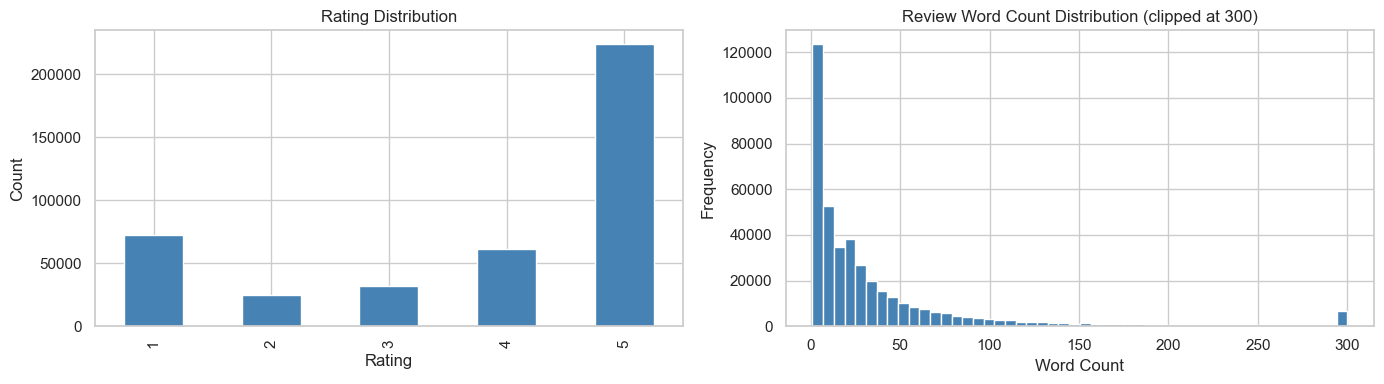

In [55]:
# Rating distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

df['Rating'].value_counts().sort_index().plot(kind='bar', ax=axes[0], color='steelblue', edgecolor='white')
axes[0].set_title('Rating Distribution')
axes[0].set_xlabel('Rating')
axes[0].set_ylabel('Count')

# Review length distribution
df['review_word_count'] = df['Reviews'].dropna().apply(lambda x: len(str(x).split()))
df['review_word_count'].clip(upper=300).plot(kind='hist', bins=50, ax=axes[1], color='steelblue', edgecolor='white')
axes[1].set_title('Review Word Count Distribution (clipped at 300)')
axes[1].set_xlabel('Word Count')

plt.tight_layout()
plt.show()

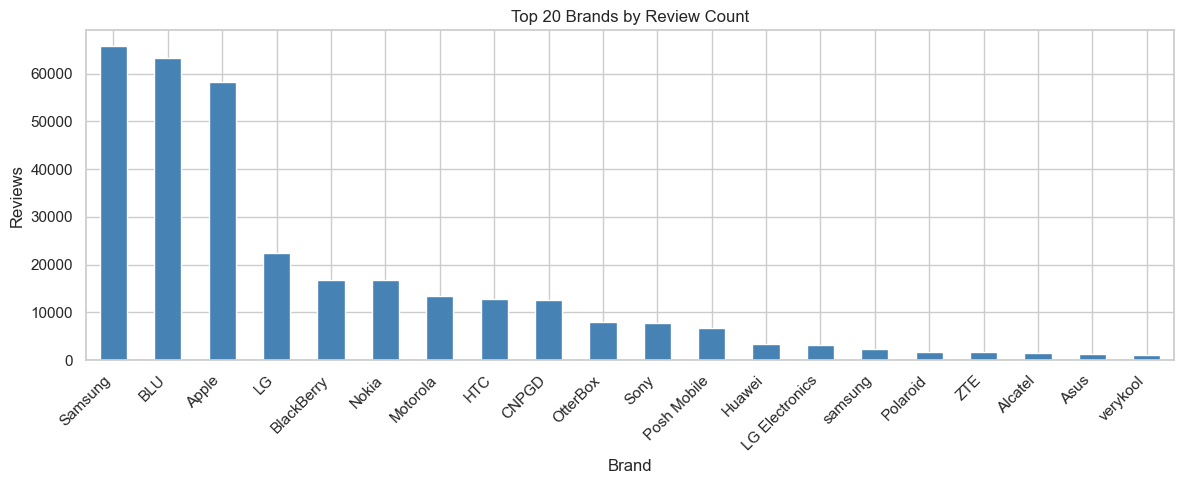

In [56]:
# Top 20 brands by review count
top_brands = df['Brand Name'].value_counts().head(20)

plt.figure(figsize=(12, 5))
top_brands.plot(kind='bar', color='steelblue', edgecolor='white')
plt.title('Top 20 Brands by Review Count')
plt.xlabel('Brand')
plt.ylabel('Reviews')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 3. Clean & Filter Reviews

In [57]:
def is_too_short(text: str, min_words: int = 5) -> bool:
    if not isinstance(text, str):
        return True
    return len(text.split()) < min_words

def is_question(text: str) -> bool:
    if not isinstance(text, str):
        return False
    text = text.strip()
    if text.endswith('?'):
        return True
    question_words = ('how', 'why', 'can', 'does', 'is', 'what', 'will', 'where', 'when', 'who')
    if text.lower().startswith(question_words):
        return True
    return False

def clean_text(text: str) -> str:
    if not isinstance(text, str):
        return ""
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

def should_keep_review(text: str) -> bool:
    if not text or not isinstance(text, str):
        return False
    if is_too_short(text):
        return False
    if is_question(text):
        return False
    return True

In [58]:
initial_count = len(df)

# Drop rows with missing reviews
df = df.dropna(subset=['Reviews'])

# Drop rows with missing Brand Name
df = df.dropna(subset=['Brand Name'])

# Clean text
df['Reviews'] = df['Reviews'].apply(clean_text)

# Apply heuristic filters
mask = df['Reviews'].apply(should_keep_review)
df = df[mask].copy()

final_count = len(df)
removed_count = initial_count - final_count

print(f'Initial rows  : {initial_count:,}')
print(f'After cleaning: {final_count:,}')
print(f'Removed       : {removed_count:,} ({100 * removed_count / initial_count:.1f}%)')

Initial rows  : 413,840
After cleaning: 261,723
Removed       : 152,117 (36.8%)


## 4. Unique Product Names

In [59]:
unique_products = df['Product Name'].dropna().unique().tolist()
print(f'Unique product names: {len(unique_products):,}')
display(unique_products[:10])

Unique product names: 3,629


['"CLEAR CLEAN ESN" Sprint EPIC 4G Galaxy SPH-D700*FRONT CAMERA*ANDROID*SLIDER*QWERTY KEYBOARD*TOUCH SCREEN',
 '"Nokia Asha 302 Unlocked GSM Phone with 3.2MP Camera, Video, QWERTY Keyboard, Wi-Fi, Bluetooth, FM Radio, SNS Integration, MP3/MP4 Player and microSD Slot - White International Version/Warranty',
 '(LANDVO) 5.0" Capacitive Touch MTK6582 Quad Core Android 4.2.2 3G Phone 512MB RAM 4GB ROM 2MP CAM WiFi GPS - Black',
 '[XMAS DEAL] [New Edition] Jethro [SC213V2] Flip Quad-band Unlocked GSM Senior & Kids Cell Phone, SOS Emergency Button, 2.4" Large LCD with Large Keypad.',
 '[XMAS DEAL] Jethro [SC118] Simple Unlocked Quad-band GSM Senior & Kids Cell Phone, SOS Button, Easy to Use, Light Weight, Large Keyboard [New Firmware Edition]',
 "10.6'' Inch E-passion Unlocked Smart Phone +Tablet='' Phablet'' Android 4.4 Kitkat Gsm,Wcdma Tablet Phone - Unlocked Dual Sim Card,Quad Core- At&t, Cricket,Straight Talk ,T-Mobile,H20,Net10 3g Phone Tablet 2G Ram 32G Rom[Free Leather Case]",
 '2.45" 

## 5. LangExtract - Model & Brand Extraction (with Checkpoint)

In [60]:
import textwrap

EXTRACTION_PROMPT = textwrap.dedent("""\
    Extract the phone brand and phone model from the product name.
    Use the exact substring from the product name as extraction_text.
    Return null brand and null model if you cannot confidently identify them.
    Do not paraphrase or invent values not present in the text.""")

EXTRACTION_EXAMPLES = [
    lx.data.ExampleData(
        text='Samsung Galaxy S7 Edge 32GB Unlocked GSM 4G LTE Phone',
        extractions=[
            lx.data.Extraction(extraction_class='brand', extraction_text='Samsung',
                               attributes={'confidence': 'high'}),
            lx.data.Extraction(extraction_class='model', extraction_text='Galaxy S7 Edge',
                               attributes={'confidence': 'high'}),
        ]
    ),
    lx.data.ExampleData(
        text='Apple iPhone 6 Plus 16GB Factory Unlocked GSM Smartphone',
        extractions=[
            lx.data.Extraction(extraction_class='brand', extraction_text='Apple',
                               attributes={'confidence': 'high'}),
            lx.data.Extraction(extraction_class='model', extraction_text='iPhone 6 Plus',
                               attributes={'confidence': 'high'}),
        ]
    ),
    # lx.data.ExampleData(
    #     text='Unlocked Android 4G LTE Dual SIM Smartphone 5.5 inch HD',
    #     extractions=[]  # No identifiable brand or model
    # ),
]

In [61]:
def load_checkpoint() -> pd.DataFrame:
    """Load existing checkpoint if it exists, otherwise return empty DataFrame."""
    if os.path.exists(CHECKPOINT_PATH):
        print(f'Checkpoint found. Loading...')
        return pd.read_csv(CHECKPOINT_PATH)
    return pd.DataFrame(columns=['product_name', 'brand_llm', 'model', 'processed'])


def save_batch_to_checkpoint(batch_results: list[dict]):
    """Append a batch of results to the checkpoint CSV."""
    os.makedirs(os.path.dirname(CHECKPOINT_PATH), exist_ok=True)
    batch_df = pd.DataFrame(batch_results)
    header = not os.path.exists(CHECKPOINT_PATH)
    batch_df.to_csv(CHECKPOINT_PATH, mode='a', index=False, header=header)


def parse_extractions(result) -> dict:
    """Parse LangExtract result into {brand_llm, model} dict."""
    brand, model = None, None
    for extraction in result.extractions:
        if extraction.extraction_class == 'brand' and brand is None:
            brand = extraction.extraction_text
        elif extraction.extraction_class == 'model' and model is None:
            model = extraction.extraction_text
    return {'brand_llm': brand, 'model': model}


RATE_LIMIT_SEMAPHORE = threading.Semaphore(16)

def extract_phone_info(product_name: str) -> dict:
    """Call LangExtract to extract brand and model from a product name string."""
    with RATE_LIMIT_SEMAPHORE:
        result = lx.extract(
            text_or_documents=product_name,
            prompt_description=EXTRACTION_PROMPT,
            examples=EXTRACTION_EXAMPLES,
            model_id='gemini-2.5-flash',
        )
        return parse_extractions(result)

In [62]:
checkpoint_df = load_checkpoint()

if not checkpoint_df.empty:
    successfully_processed = set(
        checkpoint_df.loc[checkpoint_df['processed'] == True, 'product_name'].tolist()
    )
else:
    successfully_processed = set()

to_process = [p for p in unique_products if p not in successfully_processed]

print(f'Total unique products : {len(unique_products):,}')
print(f'Already processed     : {len(successfully_processed):,}')
print(f'Remaining             : {len(to_process):,}')

Total unique products : 3,629
Already processed     : 0
Remaining             : 3,629


In [63]:
# Process in batches — each batch runs in parallel, checkpoint written after every batch
batches = [to_process[i:i + BATCH_SIZE] for i in range(0, len(to_process), BATCH_SIZE)]
counter = 1
for batch in tqdm(batches, desc='Batches'):
    batch_results = [None] * len(batch)  # preserve order
    print(f'Batch {counter} out of {len(batches)}')
    counter += 1

    with ThreadPoolExecutor(max_workers=MAX_WORKERS) as executor:
        futures = {
            executor.submit(extract_phone_info, product_name): idx
            for idx, product_name in enumerate(batch)
        }
        for future in as_completed(futures):
            idx = futures[future]
            product_name = batch[idx]
            try:
                info = future.result()
                batch_results[idx] = {
                    'product_name': product_name,
                    'brand_llm': info['brand_llm'],
                    'model': info['model'],
                    'processed': True
                }
            except Exception as e:
                print(f'  [ERROR] "{product_name[:60]}" — {e}')
                batch_results[idx] = {
                    'product_name': product_name,
                    'brand_llm': None,
                    'model': None,
                    'processed': False
                }

    save_batch_to_checkpoint(batch_results)

print('Extraction complete.')

Batches:   0%|          | 0/363 [00:00<?, ?it/s]

Batch 1 out of 363



LangExtract: model=gemini-2.5-flash [00:00]
LangExtract: model=gemini-2.5-flash, current=193 chars, processed=0 chars:  [00:00]


LangExtract: model=gemini-2.5-flash [00:00]

LangExtract: model=gemini-2.5-flash [00:00]


LangExtract: model=gemini-2.5-flash, current=239 chars, processed=0 chars:  [00:00]

LangExtract: model=gemini-2.5-flash, current=152 chars, processed=0 chars:  [00:00]



LangExtract: model=gemini-2.5-flash [00:00]



LangExtract: model=gemini-2.5-flash, current=80 chars, processed=0 chars:  [00:00]




LangExtract: model=gemini-2.5-flash [00:00]




LangExtract: model=gemini-2.5-flash, current=99 chars, processed=0 chars:  [00:00]





LangExtract: model=gemini-2.5-flash [00:00]





LangExtract: model=gemini-2.5-flash, current=105 chars, processed=0 chars:  [00:00]






LangExtract: model=gemini-2.5-flash [00:00]








LangExtract: model=gemini-2.5-flash [00:00]







LangExtract: model=gemini-2.5-flash [00:00]






LangExtract: model=gemini-2.5-flash, current

Batch 2 out of 363



LangExtract: model=gemini-2.5-flash [00:00]
LangExtract: model=gemini-2.5-flash, current=91 chars, processed=0 chars:  [00:00]

LangExtract: model=gemini-2.5-flash [00:00]

LangExtract: model=gemini-2.5-flash, current=195 chars, processed=0 chars:  [00:00]


LangExtract: model=gemini-2.5-flash [00:00]


LangExtract: model=gemini-2.5-flash, current=74 chars, processed=0 chars:  [00:00]



LangExtract: model=gemini-2.5-flash [00:00]




LangExtract: model=gemini-2.5-flash [00:00]



LangExtract: model=gemini-2.5-flash, current=125 chars, processed=0 chars:  [00:00]




LangExtract: model=gemini-2.5-flash, current=118 chars, processed=0 chars:  [00:00]






LangExtract: model=gemini-2.5-flash [00:00]





LangExtract: model=gemini-2.5-flash [00:00]






LangExtract: model=gemini-2.5-flash, current=193 chars, processed=0 chars:  [00:00]





LangExtract: model=gemini-2.5-flash, current=103 chars, processed=0 chars:  [00:00]







LangExtract: model=gemini-2.5-flash [00:00]









Lan

Batch 3 out of 363


... (740 outputs left out)


LangExtract: model=gemini-2.5-flash [00:00]
LangExtract: model=gemini-2.5-flash, current=102 chars, processed=0 chars:  [00:00]

LangExtract: model=gemini-2.5-flash [00:00]

LangExtract: model=gemini-2.5-flash, current=36 chars, processed=0 chars:  [00:00]


LangExtract: model=gemini-2.5-flash [00:00]


LangExtract: model=gemini-2.5-flash, current=28 chars, processed=0 chars:  [00:00]




LangExtract: model=gemini-2.5-flash [00:00]



LangExtract: model=gemini-2.5-flash [00:00]




LangExtract: model=gemini-2.5-flash, current=36 chars, processed=0 chars:  [00:00]



LangExtract: model=gemini-2.5-flash, current=11 chars, processed=0 chars:  [00:00]





LangExtract: model=gemini-2.5-flash [00:00]





LangExtract: model=gemini-2.5-flash, current=104 chars, processed=0 chars:  [00:00]






LangExtract: model=gemini-2.5-flash [00:00]






LangExtract: model=gemini-2.5-flash, current=152 chars, processed=0 chars:  [00:00]









LangExtract: model=gemini-2.5-flash [00:00]








Lang

Batch 363 out of 363



LangExtract: model=gemini-2.5-flash [00:00]

LangExtract: model=gemini-2.5-flash [00:00]
LangExtract: model=gemini-2.5-flash, current=136 chars, processed=0 chars:  [00:00]

LangExtract: model=gemini-2.5-flash, current=25 chars, processed=0 chars:  [00:00]


LangExtract: model=gemini-2.5-flash [00:00]



LangExtract: model=gemini-2.5-flash [00:00]


LangExtract: model=gemini-2.5-flash, current=93 chars, processed=0 chars:  [00:00]



LangExtract: model=gemini-2.5-flash, current=40 chars, processed=0 chars:  [00:00]




LangExtract: model=gemini-2.5-flash [00:00]




LangExtract: model=gemini-2.5-flash, current=87 chars, processed=0 chars:  [00:00]





LangExtract: model=gemini-2.5-flash [00:00]





LangExtract: model=gemini-2.5-flash, current=85 chars, processed=0 chars:  [00:00]






LangExtract: model=gemini-2.5-flash [00:00]






LangExtract: model=gemini-2.5-flash, current=69 chars, processed=0 chars:  [00:00]







LangExtract: model=gemini-2.5-flash [00:00]







LangExtra

Extraction complete.


In [64]:
# Reload full checkpoint and merge into main dataframe
checkpoint_df = pd.read_csv(CHECKPOINT_PATH)

print(f'Checkpoint rows : {len(checkpoint_df):,}')
print(f'Processed       : {checkpoint_df["processed"].sum():,}')
print(f'Failed          : {(~checkpoint_df["processed"]).sum():,}')
print(f'Model null      : {checkpoint_df["model"].isna().sum():,}')

checkpoint_df.head()

Checkpoint rows : 3,629
Processed       : 3,616
Failed          : 13
Model null      : 310


,product_name,brand_llm,model,processed
0,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",NaN,EPIC 4G Galaxy SPH-D700,True
1,"""Nokia Asha 302 Unlocked GSM Phone with 3.2MP ...",Nokia,Asha 302,True
2,"(LANDVO) 5.0"" Capacitive Touch MTK6582 Quad Co...",LANDVO,NaN,True
3,[XMAS DEAL] [New Edition] Jethro [SC213V2] Fli...,Jethro,SC213V2 Flip,True
4,[XMAS DEAL] Jethro [SC118] Simple Unlocked Qua...,Jethro,SC118,True


In [65]:
# Merge — keep only the Model column from LangExtract; original Brand Name stays untouched
df = df.merge(
    checkpoint_df[['product_name', 'model']],
    left_on='Product Name',
    right_on='product_name',
    how='left'
).drop(columns=['product_name'])

print(f'Final dataset shape: {df.shape}')
df[['Product Name', 'Brand Name', 'model']].drop_duplicates().head(10)

Final dataset shape: (261723, 8)


,Product Name,Brand Name,model
0,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,EPIC 4G Galaxy SPH-D700
34,"""Nokia Asha 302 Unlocked GSM Phone with 3.2MP ...",Nokia,Asha 302
83,"(LANDVO) 5.0"" Capacitive Touch MTK6582 Quad Co...",HTM,NaN
96,[XMAS DEAL] [New Edition] Jethro [SC213V2] Fli...,Jethro,SC213V2 Flip
132,[XMAS DEAL] Jethro [SC118] Simple Unlocked Qua...,Jethro,SC118
198,10.6'' Inch E-passion Unlocked Smart Phone +Ta...,e passion,NaN
208,"2.45"" UNLOCKED Rugged Micro Android Smart Phon...",Cedar Tree Technologies,NaN
212,"2016 GSM Factory Unlocked! Smartphone 6"" QHD A...",Indigi,NaN
213,2016 Latest Mini6 Small Android 5.1 Smart Mobi...,Phone Baby,NaN
214,2016 Latest Mini6 Small Android 5.1 Smart Mobi...,Phone Baby,NaN


## 6. Save Final Dataset

In [66]:
os.makedirs(os.path.dirname(OUTPUT_PATH), exist_ok=True)
df.drop(columns=['review_word_count'], errors='ignore').to_csv(OUTPUT_PATH, index=False)
print(f'Saved {len(df):,} rows to {OUTPUT_PATH}')
df.head()

Saved 261,723 rows to ../data/reviews_cleaned.csv


,Product Name,Brand Name,Price,Rating,Reviews,Review Votes,review_word_count,model
0,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,5,I feel so LUCKY to have found this used (phone...,1.0,72.0,EPIC 4G Galaxy SPH-D700
1,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,"nice phone, nice up grade from my pantach revu...",0.0,40.0,EPIC 4G Galaxy SPH-D700
2,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,It works good but it goes slow sometimes but i...,0.0,17.0,EPIC 4G Galaxy SPH-D700
3,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,Great phone to replace my lost phone. The only...,0.0,43.0,EPIC 4G Galaxy SPH-D700
4,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,1,I already had a phone with problems... I know ...,1.0,80.0,EPIC 4G Galaxy SPH-D700


## 7. Preview of processed dataset

In [67]:
df[['Product Name', 'Brand Name', 'model', 'Reviews', 'Rating']].sample(10)

,Product Name,Brand Name,model,Reviews,Rating
61596,BLU Advance 4.0L Unlocked Smartphone -US GSM -...,BLU,Advance 4.0L,Very happy with the performance. The apps work...,4
20419,Apple iPhone 5c 32GB (Yellow) - AT&T,Apple,iPhone 5c,It was a great device but the sound needs impr...,4
182366,OtterBox Protective Defender Case for Apple iP...,OtterBox,iPhone 5,"Great cover, confident it will protect my phone.",4
92194,BLU Studio C 5+5 Smartphone with Lollipop OS- ...,BLU,Studio C 5+5,Still pretty earlier still trying to familiari...,4
256734,Verizon LG Extravert No Contract QWERTY 2MP Ca...,LG,Extravert,Good phone for an extra.,5
100892,"BLU VIVO 5 Smartphone -5.5"" 4G LTE GSM Unlocke...",BLU,VIVO 5,Battery does not last. Constantly shuts off. I...,1
176892,Nokia N9 Unlocked GSM Phone with 64 GB Interna...,Nokia,N9,I hate this phone because it is not good phone...,1
67652,"BLU DASH M2 - 5.0"" Smartphone - US GSM Unlocke...",BLU,DASH M2,Boo i didnt even put anything on it and there ...,1
189602,"Posh Mobile Memo S580a - 5.8"" Display, 4G H+ G...",Posh Mobile,Memo S580a,Just wish more options for cases. Love the phone.,4
26069,Apple iPhone 5S 16GB Gold GSM Unlocked (Certif...,Apple,iPhone 5S,It serves the purpose I bought it to serve!,3


In [68]:
# Missing model / brand stats
total = len(df)
missing_model = df['model'].isna().sum()
missing_brand = df['Brand Name'].isna().sum()

print(f"Missing model : {missing_model:,} ({100 * missing_model / total:.1f}%)")
print(f"Missing brand : {missing_brand:,} ({100 * missing_brand / total:.1f}%)")

Missing model : 16,163 (6.2%)
Missing brand : 0 (0.0%)


In [69]:
# Drop rows where model could not be extracted
df_final = df.dropna(subset=['model']).copy()
print(f"Before : {len(df):,}")
print(f"After  : {len(df_final):,}")
print(f"Dropped: {len(df) - len(df_final):,}")

Before : 261,723
After  : 245,560
Dropped: 16,163


In [72]:
# Preview long reviews
long_reviews = df_final[df_final['review_word_count'] > 1000]
print(f"Reviews over 1000 words: {len(long_reviews):,} ({100 * len(long_reviews) / len(df_final):.1f}%)")
long_reviews[['Product Name', 'Brand Name', 'model', 'review_word_count', 'Reviews']].sample(5)

Reviews over 1000 words: 326 (0.1%)


,Product Name,Brand Name,model,review_word_count,Reviews
233220,Samsung Galaxy S6 Factory Unlocked 32GB Smartp...,Samsung,Galaxy S6,1281.0,I wish people would not slam a product and ske...
127983,Huawei Ascend Mate 7 Factory Unlocked Cellphon...,HUAWEI,Ascend Mate 7,3014.0,(Update below)PROS1. Most modern Android flags...
73332,Blu LIFE 8 Unlocked (Pink),BLU,LIFE 8,1276.0,UPDATE:Don't buy this crap. A month after my 6...
250050,Sony Xperia Z5 E6653 32GB 5.2-inch 4G LTE Fact...,Sony,Xperia Z5 E6653,1010.0,"Alright so after about a full month of using, ..."
158131,Motorola KRZR K1 Unlocked Cell Phone with 2 MP...,Motorola,KRZR K1,1156.0,I'm rating this 3 stars as a phone with text m...


In [76]:
# Inspect full text of a single long review
sample = long_reviews.sample(1).iloc[0]
print(f"Word count: {sample['review_word_count']}")
print(f"Product   : {sample['Product Name']}")
print("---")
print(sample['Reviews'])

Word count: 1112.0
Product   : Nokia E71 Unlocked Phone with 3.2 MP Camera, 3G, Media Player, GPS with Free Voice Navigation, Wi-Fi, and MicroSD Slot--U.S. Version with Warranty (White)
---
Because, this is my first smartphone experience (I've never even played with one before), please put this review into context.I bought this phone when Amazon did a one day $200 sale on the phone, because my wife needed a smartphone for a new job. She's Japanese, so she's used to high tech, next gen phones, but she's never been a phone person. In Japan you can get phones with crazy features that are still easy to use. I also liked the fact that you can use this phone as a stand alone GPS device without having the service. The phone actually is great for that, even though the screen is small. Needless to say the phone was too complected for my wife to like. She's very busy and doesn't have time that this phone needs to figure out.I fell in love with it, because I like thinner flip phones, and this pho

## 8. Save to SQLite for faster search

In [78]:
conn = sqlite3.connect(DB_PATH)

df_final = df_final.reset_index(drop=True)
df_final.index.name = 'id'
df_final.to_sql('reviews', conn, if_exists='replace', index=True)

# Indexes for fast lookup
conn.execute('CREATE INDEX IF NOT EXISTS idx_brand_model ON reviews ("Brand Name", model)')
conn.execute('CREATE INDEX IF NOT EXISTS idx_helpful ON reviews ("helpful votes")')
conn.commit()
conn.close()

print(f"Saved to {DB_PATH}")

Saved to ../data/reviews.db
